# App Code Coverage Analysis

 In this notebook, we analyze the code coverage of the instrumented firmware packages using the reports generated by ACVTool. We will:
1. Identify valid firmware folders containing ACV reports.
2. Parse the HTML reports to extract coverage data.

**Prerequisites**
- Ensure you have the `acvtool_html_parser.py` script in the same directory as this notebook. This script is responsible for parsing the ACVTool HTML reports and generating CSV summaries.
- Before you can run this notebook, make sure to have the ACVTool reports generated and placed in the expected directory structure under `./data/{DATASET_DIR_NAME}/emulator_out/{firmware_folder}/acv_reports/`.
  - You can generate these reporty by running the docker container under ./docker/acvtoo-report/ (see README.md for details).
```
# Fetch the pickle files from the remote server
python3 ./fetch_pickles.py --max-workers 3 --progress-interval 5 --emulator-out ./data/02_octopus/emulator_out

# Generate the ACVTool reports using the provided Docker container:
docker build -t acvtool-report:2.3.6 .
python3 ./generate_compose.py --output docker-compose.yml --emulator-out ./data/02_octopus/emulator_out
./run_batched.sh
# Collect all reports into a single folder
python3 ./collect_reports.py --emulator-out ./data/02_octopus/emulator_out

# Optional Upload results to repository
python3 ./acv_upload.py --url https://nexus.example.org:8443/repository/raw_files/ --user YYYYY --password XXXXXX --prefix "acvtool_reports_" --target-folder "acv_reports" --input-path /home/user/storage/FMD-AECS/emulator/emulator_out/ --output-file /home/user/storage/FMD-AECS/emulator/acvtool-report/uploaded_reports.txt

# Collect all reports into a single csv file
python3 ./acvtool_html_parser.py --emulator-out ./data/02_octopus/emulator_out --out-dir ./data/02_octopus/coverage/ --csv coverage_summary.csv
```
After running the above commands, you should have the ACVTool reports generated as one CSV file and stored in the appropriate directory. You can then proceed with the code coverage analysis in this notebook.

In [7]:
import sys
!{sys.executable} -m pip install requests pandas bs4 matplotlib seaborn
%pip install scipy


[notice] A new release of pip is available: 25.3 -> 26.2.1
[notice] To update, run: /Users/tom/Documents/python12_venv/bin/python3 -m pip install --upgrade pip

[notice] A new release of pip is available: 25.3 -> 26.2.1
[notice] To update, run: /Users/tom/Documents/python12_venv/bin/python3 -m pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [8]:
REPORTS_CSV_FILE_PATH = "./data/02_octopus/coverage/coverage_summary.csv"

In [9]:
import pandas as pd

df_coverage = pd.read_csv(REPORTS_CSV_FILE_PATH)
print(df_coverage.columns)
df_coverage.head()

Index(['Element', 'Ratio', 'Cov.', 'Missed', 'Lines', 'Missed.1', 'Methods',
       'Missed.2', 'Classes', 'Source_Path', 'Firmware_ID', 'Package'],
      dtype='str')


,Element,Ratio,Cov.,Missed,Lines,Missed.1,Methods,Missed.2,Classes,Source_Path,Firmware_ID,Package
0,1,0 of 673,0.00000%,673,673,28,28,5,5,/home/user/storage/FMD-AECS/emulator/emulator_...,68b0892a65e2ad36cfab2516_v12_sdk_phone64_arm64...,com.android.calllogbackup
1,1,0 of 347,0.00000%,347,347,30,30,6,6,/home/user/storage/FMD-AECS/emulator/emulator_...,68b0892a65e2ad36cfab2516_v12_sdk_phone64_arm64...,com.android.backupconfirm
2,1,0 of 1372,0.00000%,1372,1372,89,89,11,11,/home/user/storage/FMD-AECS/emulator/emulator_...,68b0892a65e2ad36cfab2516_v12_sdk_phone64_arm64...,com.android.carrierdefaultapp
3,1,2 of 10,20.00000%,8,10,5,7,0,1,/home/user/storage/FMD-AECS/emulator/emulator_...,68b0892a65e2ad36cfab2516_v12_sdk_phone64_arm64...,com.android.bookmarkprovider
4,1,0 of 1766,0.00000%,1766,1766,170,170,21,21,/home/user/storage/FMD-AECS/emulator/emulator_...,68b0892a65e2ad36cfab2516_v12_sdk_phone64_arm64...,com.android.cameraextensions


In [10]:
total_rows = len(df_coverage['Firmware_ID'])
print(total_rows)

total_rows = len(df_coverage['Firmware_ID'].unique())
print(total_rows)

2043
53


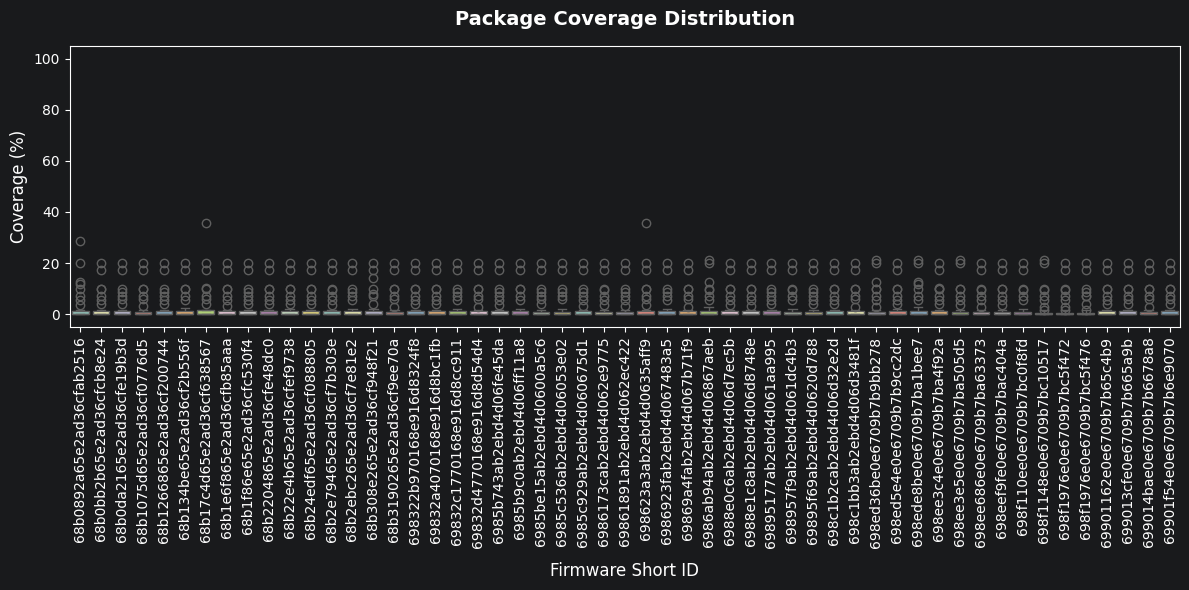

In [11]:
import matplotlib.pyplot as plt
import os
import pandas as pd
import seaborn as sns

# --- 1. Fix the Coverage Parsing (String to Float) ---
df_coverage['Cov.'] = df_coverage['Cov.'].astype(str).str.rstrip('%').astype(float)


# --- 2. Extract the Short Firmware ID from the Path ---
def extract_short_firmware_id(long_firmware_id):
    parts = str(long_firmware_id).split("_")
    return parts[0]

df_coverage['Firmware_ID_Short'] = df_coverage['Firmware_ID'].apply(extract_short_firmware_id)


# --- 3. Build the Boxplot Grouped by Firmware ---
plt.figure(figsize=(12, 6))

sns.boxplot(
    data=df_coverage,
    x='Firmware_ID_Short',
    y='Cov.',
    palette='Set3',
    hue='Firmware_ID_Short',
    legend=False
)

# --- 4. Presentation Adjustments ---
plt.title('Package Coverage Distribution', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Firmware Short ID', fontsize=12, labelpad=10)
plt.ylabel('Coverage (%)', fontsize=12)

plt.xticks(rotation=90) # Short IDs fit easily, no heavy rotation needed
plt.ylim(-5, 105)      # Gives breathing room to see 0% and 100% bounds clearly

plt.tight_layout()
plt.show()

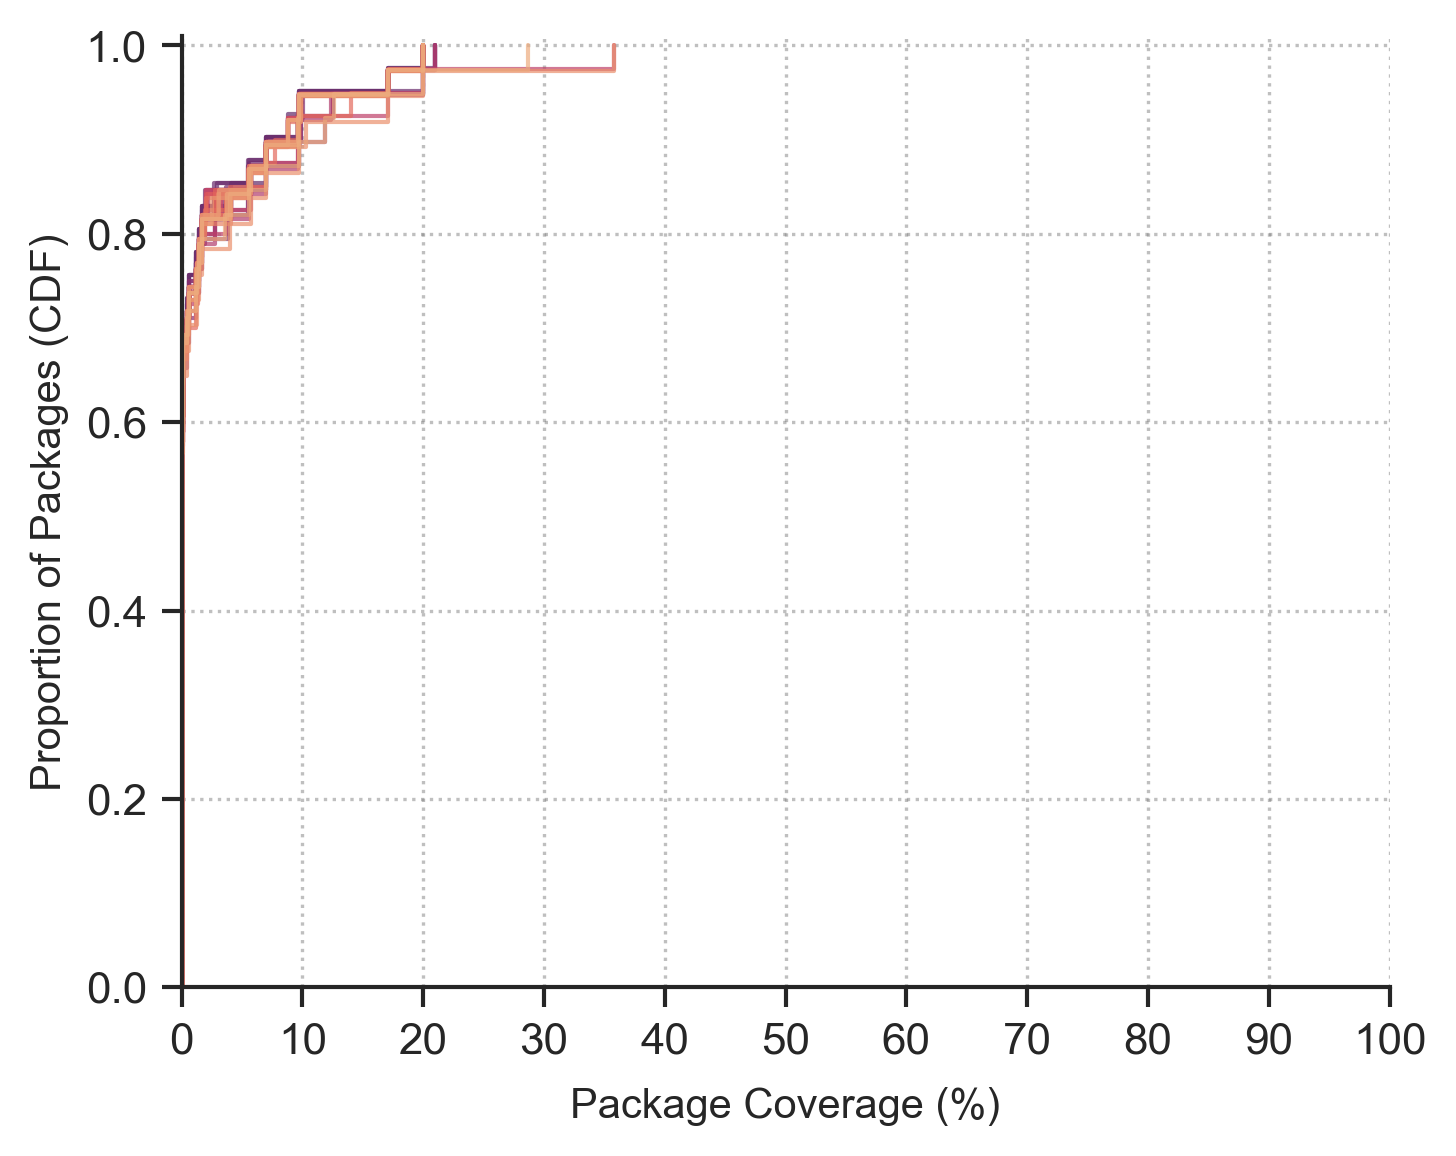

In [12]:
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker  # Import the ticker module
import seaborn as sns

# 1. Set the publication style context
sns.set_context("paper", font_scale=1.2)
sns.set_style("ticks")

# 2. Size optimized for publication
fig, ax = plt.subplots(figsize=(5, 4), dpi=300)

# 3. Plot the ECDF
sns.ecdfplot(
    data=df_coverage,
    x='Cov.',
    hue='Firmware_ID_Short',
    palette='flare',
    linewidth=1.0,
    alpha=0.7,
    legend=False,
    ax=ax
)

# 4. Typography & Labels
#ax.set_title('Package Coverage Cumulative Distribution', fontsize=12, pad=10)
ax.set_xlabel('Package Coverage (%)', fontsize=10, labelpad=6)
ax.set_ylabel('Proportion of Packages (CDF)', fontsize=10)

# 5. Fine-Tuning Axis Limits & Ticks
ax.set_xlim(0, 100)
ax.set_ylim(0, 1.01)

# --- Fix: Set X-Axis Ticks every 10% ---
ax.xaxis.set_major_locator(ticker.MultipleLocator(10))

sns.despine(ax=ax)

# 6. Subtle background grid (aligns perfectly with your new 10% ticks)
ax.grid(True, linestyle=':', alpha=0.5, color='gray')

plt.tight_layout()
plt.savefig('./images/coverage_cdf.pdf', bbox_inches='tight', dpi=300)
plt.show()


# How to interpret this plot:The X-axis shows your coverage percentage ($0\%$ to $100\%$).The Y-axis shows the proportion of packages. For example, if you look at $Y = 0.5$ (the $50$th percentile) and move horizontally to meet a line, the corresponding X value tells you that $50\%$ of your packages have that coverage percentage or lower.Steep vertical jumps mean a massive number of packages share that exact same coverage score (often at $0\%$ or $100\%$).


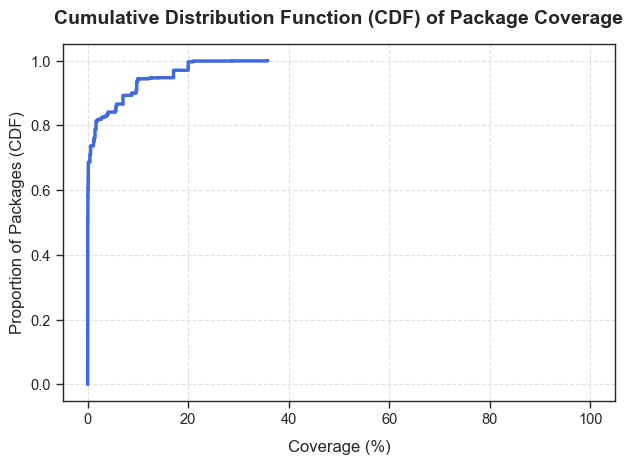

In [13]:
# If you just want ONE overall curve for all data combined,
sns.ecdfplot(data=df_coverage, x='Cov.', linewidth=2.5, color='royalblue')

# --- 4. Presentation Adjustments ---
plt.title('Cumulative Distribution Function (CDF) of Package Coverage', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Coverage (%)', fontsize=12, labelpad=10)
plt.ylabel('Proportion of Packages (CDF)', fontsize=12)

# Gridlines make reading percentages at specific proportions much easier
plt.grid(True, linestyle='--', alpha=0.6)

plt.xlim(-5, 105)      # Matches your boxplot bounds
plt.ylim(-0.05, 1.05)  # ECDF proportions go from 0.0 to 1.0

plt.tight_layout()
plt.show()

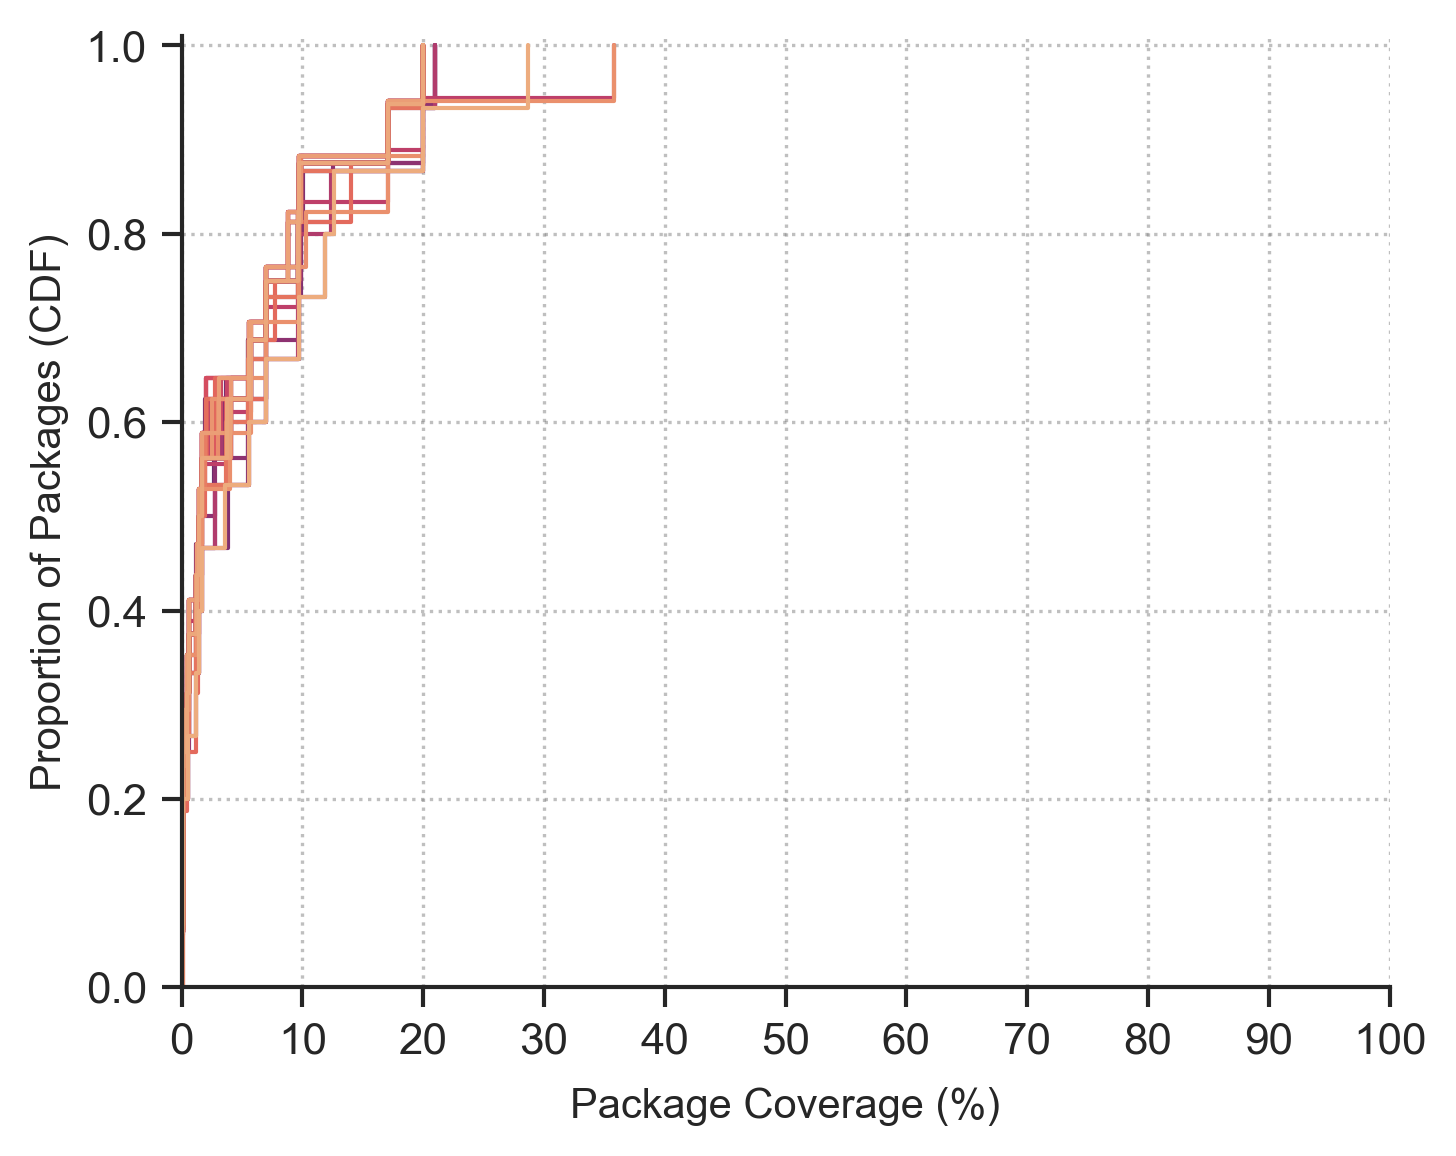

In [14]:
import pandas as pd # Ensure pandas is imported if not already
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
import seaborn as sns

# --- Filter out packages with 0.05% coverage or lower ---
df_filtered = df_coverage[df_coverage['Cov.'] > 0.05]

# 1. Set the publication style context
sns.set_context("paper", font_scale=1.2)
sns.set_style("ticks")

# 2. Size optimized for publication
fig, ax = plt.subplots(figsize=(5, 4), dpi=300)

# 3. Plot the ECDF using the filtered data
sns.ecdfplot(
    data=df_filtered,   # Use the new filtered dataframe here
    x='Cov.',
    hue='Firmware_ID_Short',
    palette='flare',
    linewidth=1.0,
    legend=False,
    ax=ax
)

# 4. Typography & Labels
ax.set_xlabel('Package Coverage (%)', fontsize=10, labelpad=6)
ax.set_ylabel('Proportion of Packages (CDF)', fontsize=10)

# 5. Fine-Tuning Axis Limits & Ticks
ax.set_xlim(0, 100)
ax.set_ylim(0, 1.01)

# Set X-Axis Ticks every 10%
ax.xaxis.set_major_locator(ticker.MultipleLocator(10))

sns.despine(ax=ax)

# 6. Subtle background grid
ax.grid(True, linestyle=':', alpha=0.5, color='gray')

plt.tight_layout()

# Save to a new filename so you have both versions
plt.savefig('./images/coverage_ecdf_filtered.pdf', bbox_inches='tight', dpi=300)
plt.show()

In [15]:
import pandas as pd

# Assuming df_coverage is your original dataframe
# and df_filtered is already created: df_filtered = df_coverage[df_coverage['Cov.'] > 0.05]

# Count total packages per firmware
total_apps = df_coverage.groupby('Firmware_ID_Short').size().rename('Total Packages')

# Count packages that actually have coverage (> 0.05%)
covered_apps = df_filtered.groupby('Firmware_ID_Short').size().rename('Executed with Coverage')

# Combine into a single summary DataFrame
df_stats = pd.concat([total_apps, covered_apps], axis=1).fillna(0).astype(int)

# Calculate the success rate percentage
df_stats['Success Rate (%)'] = ((df_stats['Executed with Coverage'] / df_stats['Total Packages']) * 100).round(2)

print("--- Coverage Execution Statistics ---")
print(df_stats)

--- Coverage Execution Statistics ---
                          Total Packages  Executed with Coverage  \
Firmware_ID_Short                                                  
68b0892a65e2ad36cfab2516              39                      15   
68b0bb2b65e2ad36cfcb8e24              38                      16   
68b0da2165e2ad36cfe19b3d              38                      16   
68b1075d65e2ad36cf0776d5              39                      17   
68b1266865e2ad36cf200744              38                      17   
68b134be65e2ad36cf2b556f              37                      16   
68b17c4d65e2ad36cf638567              37                      17   
68b1e6f865e2ad36cfb85aaa              38                      16   
68b1f86e65e2ad36cfc530f4              38                      16   
68b2204865e2ad36cfe48dc0              37                      16   
68b22e4b65e2ad36cfef9738              39                      17   
68b24edf65e2ad36cf088805              38                      16   
68b2e79465

/var/folders/f_/b80d8wfj0bnckn_1q79yv01m0000gn/T/ipykernel_15008/530764961.py:12: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(


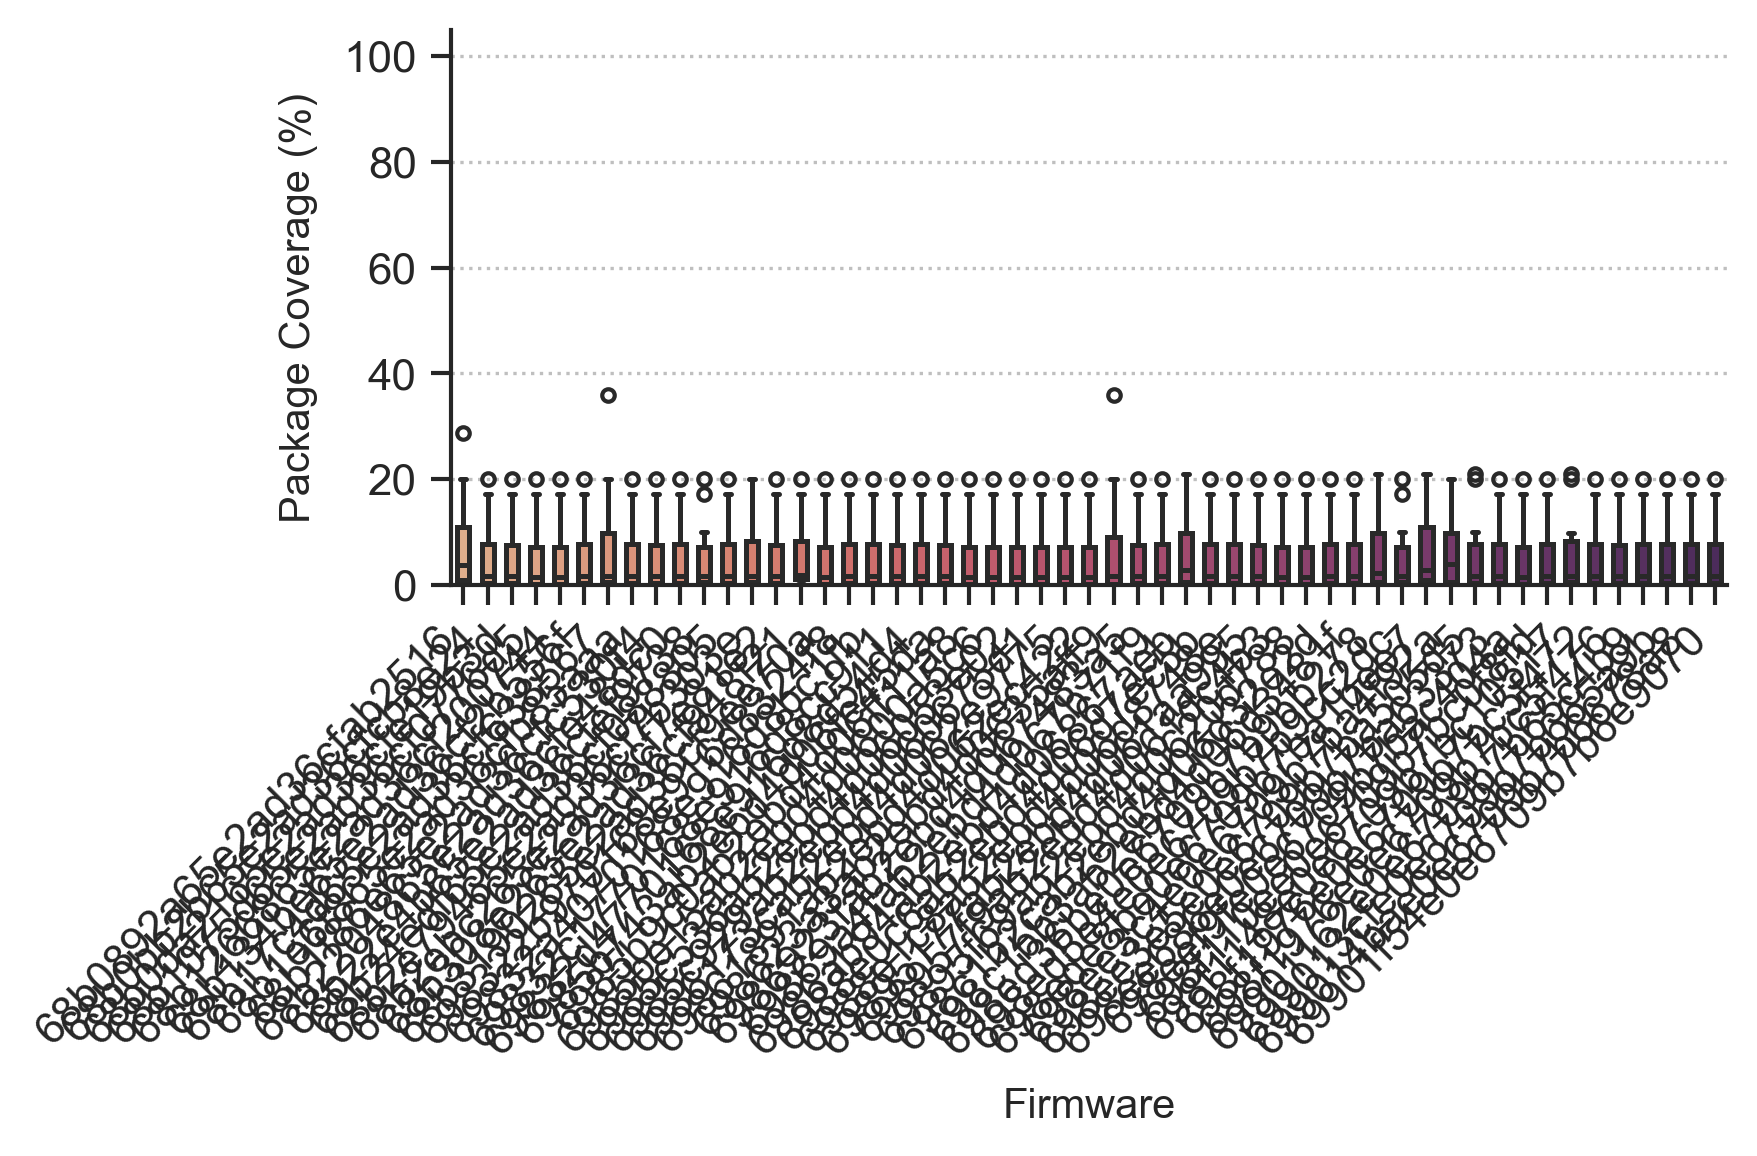

In [16]:
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Set the publication style context
sns.set_context("paper", font_scale=1.2)
sns.set_style("ticks")

# 2. Size optimized for publication (slightly wider to fit firmware labels)
fig, ax = plt.subplots(figsize=(6, 4), dpi=300)

# 3. Plot the Boxplot using the FILTERED data
sns.boxplot(
    data=df_filtered,
    x='Firmware_ID_Short',
    y='Cov.',
    palette='flare',
    width=0.5,       # Makes the boxes look a bit sleeker
    linewidth=1.2,
    fliersize=3,     # Size of outlier dots
    ax=ax
)

# 4. Typography & Labels
ax.set_ylabel('Package Coverage (%)', fontsize=10, labelpad=6)
ax.set_xlabel('Firmware', fontsize=10, labelpad=6)

# 5. Fine-Tuning Axis Limits & Ticks
ax.set_ylim(0, 105) # Slightly above 100 so top whiskers/outliers aren't cut off

# Rotate X-axis labels if firmware names are long and overlap
plt.xticks(rotation=45, ha='right')

sns.despine(ax=ax)

# 6. Subtle background grid for the Y-axis to easily read coverage percentages
ax.yaxis.grid(True, linestyle=':', alpha=0.5, color='gray')
ax.xaxis.grid(False)

plt.tight_layout()
plt.savefig('./images/coverage_boxplot_filtered.pdf', bbox_inches='tight', dpi=300)
plt.show()

In [17]:
import pandas as pd

# 1. Total Apps
total_apps = df_coverage.groupby('Firmware_ID_Short').size().rename('Total Apps')

# 2. Filtered for executed apps (Cov > 0.05)
df_filtered = df_coverage[df_coverage['Cov.'] > 0.05]
executed_apps = df_filtered.groupby('Firmware_ID_Short').size().rename('Executed Apps')

# 3. Statistics on filtered data (Quantiles and Median)
stats = df_filtered.groupby('Firmware_ID_Short')['Cov.'].agg([
    ('Q1 (25\\%)', lambda x: x.quantile(0.25)),
    ('Median (50\\%)', 'median'),
    ('Q3 (75\\%)', lambda x: x.quantile(0.75))
])

# 4. Combine all into one summary DataFrame
df_summary = pd.concat([total_apps, executed_apps, stats], axis=1).reset_index()

# 5. Rename columns for a cleaner LaTeX table
df_summary.rename(columns={'Firmware_ID_Short': 'Firmware'}, inplace=True)

# 6. Generate LaTeX code using pandas' built-in to_latex()
latex_table = df_summary.to_latex(
    index=False,
    float_format="%.1f",
    column_format="lccccc",  # l for left alignment (Firmware), c for center (Stats)
    caption="Coverage statistics per firmware. Executed apps are defined as having $>$0.05\\% coverage.",
    label="tab:coverage_stats",
    escape=False # Prevents escaping the % signs we added to headers
)

# Print the latex code so you can copy/paste it into your paper
print(latex_table)

# Optionally, save it directly to a file
with open('./images/coverage_statistics.tex', 'w') as f:
    f.write(latex_table)

\begin{table}
\caption{Coverage statistics per firmware. Executed apps are defined as having $>$0.05\% coverage.}
\label{tab:coverage_stats}
\begin{tabular}{lccccc}
\toprule
Firmware & Total Apps & Executed Apps & Q1 (25\%) & Median (50\%) & Q3 (75\%) \\
\midrule
68b0892a65e2ad36cfab2516 & 39 & 15 & 0.9 & 3.6 & 10.8 \\
68b0bb2b65e2ad36cfcb8e24 & 38 & 16 & 0.4 & 1.6 & 7.7 \\
68b0da2165e2ad36cfe19b3d & 38 & 16 & 0.4 & 1.6 & 7.5 \\
68b1075d65e2ad36cf0776d5 & 39 & 17 & 0.1 & 1.5 & 7.0 \\
68b1266865e2ad36cf200744 & 38 & 17 & 0.1 & 1.5 & 7.0 \\
68b134be65e2ad36cf2b556f & 37 & 16 & 0.4 & 1.6 & 7.7 \\
68b17c4d65e2ad36cf638567 & 37 & 17 & 0.4 & 1.7 & 9.8 \\
68b1e6f865e2ad36cfb85aaa & 38 & 16 & 0.4 & 1.6 & 7.7 \\
68b1f86e65e2ad36cfc530f4 & 38 & 16 & 0.4 & 1.6 & 7.5 \\
68b2204865e2ad36cfe48dc0 & 37 & 16 & 0.4 & 1.6 & 7.7 \\
68b22e4b65e2ad36cfef9738 & 39 & 17 & 0.4 & 1.7 & 7.0 \\
68b24edf65e2ad36cf088805 & 38 & 16 & 0.4 & 1.6 & 7.7 \\
68b2e79465e2ad36cf7b303e & 38 & 15 & 0.5 & 1.7 & 8.3 \\
68b2ebc

In [23]:
import pandas as pd

# 1. Filtered dataset for executed apps (Cov > 0.05)
df_filtered = df_coverage[df_coverage['Cov.'] > 0.05]

# 2. Calculate overall metrics
total_apps = len(df_coverage)
executed_apps = len(df_coverage)
executed_apps_with_cov = len(df_filtered)
exec_rate = (executed_apps_with_cov / total_apps) * 100 if total_apps > 0 else 0
mean_cov = df_filtered['Cov.'].mean()
max_cov = df_filtered['Cov.'].max()
q1 = df_filtered['Cov.'].quantile(0.25)
median = df_filtered['Cov.'].median()
q3 = df_filtered['Cov.'].quantile(0.75)

# 3. Create a Transposed summary DataFrame (Metrics as rows)
df_transposed = pd.DataFrame({
    'Metric': [
        'Total Apps',
        'Executed Apps',
        'Apps with Coverage',
        'Execution Rate (\\%)',
        'Mean Coverage (\\%)',
        'Q1 (25\\%)',
        'Median (50\\%)',
        'Q3 (75\\%)',
        'Max Coverage (\\%)'
    ],
    'Value': [
        total_apps,
        executed_apps,
        executed_apps_with_cov,
        exec_rate,
        mean_cov,
        q1,
        median,
        q3,
        max_cov
    ]
})

# 4. Generate LaTeX code
latex_table_transposed = df_transposed.to_latex(
    index=False,
    float_format="%.1f",
    column_format="lr", # Left align metric names, right align numbers
    caption="Overall coverage statistics for the entire dataset.",
    label="tab:coverage_stats_overall",
    escape=False # Prevents escaping the % signs
)

print(latex_table_transposed)

with open('./images/coverage_statistics_overall.tex', 'w') as f:
    f.write(latex_table_transposed)

\begin{table}
\caption{Overall coverage statistics for the entire dataset.}
\label{tab:coverage_stats_overall}
\begin{tabular}{lr}
\toprule
Metric & Value \\
\midrule
Total Apps & 2043.0 \\
Executed Apps & 2043.0 \\
Apps with Coverage & 859.0 \\
Execution Rate (\%) & 42.0 \\
Mean Coverage (\%) & 5.0 \\
Q1 (25\%) & 0.1 \\
Median (50\%) & 1.7 \\
Q3 (75\%) & 8.8 \\
Max Coverage (\%) & 35.8 \\
\bottomrule
\end{tabular}
\end{table}



In [19]:
# --- 1. Calculate the Median Coverage for Each Firmware ---
# Group by the short ID and calculate the median of the 'Cov.' column
df_medians = df_coverage.groupby('Firmware_ID_Short')['Cov.'].median().reset_index()

# Rename columns for clear presentation
df_medians.columns = ['Firmware Short ID', 'Median Coverage (%)']

# Sort from highest coverage to lowest coverage
df_medians_sorted = df_medians.sort_values(by='Median Coverage (%)', ascending=False)


# --- 2. Print Summary for Main Text (Top 5 / Bottom 5) ---
overall_median = df_coverage['Cov.'].median()

print(f"Overall Dataset Median Coverage: {overall_median:.2f}%\n")
print("=== TOP 5 FIRMWARES BY MEDIAN COVERAGE ===")
print(df_medians_sorted.head(5).to_string(index=False, float_format=lambda x: f"{x:.2f}%"))

print("\n=== BOTTOM 5 FIRMWARES BY MEDIAN COVERAGE ===")
print(df_medians_sorted.tail(5).to_string(index=False, float_format=lambda x: f"{x:.2f}%"))


# --- 3. Optional: Export the Full 70-Row Table straight to LaTeX or Markdown ---
# For a LaTeX appendix:
# print(df_medians_sorted.to_latex(index=False, float_format="%.2f%%"))

# For a Markdown file/notebook view:
# print(df_medians_sorted.to_markdown(index=False))

Overall Dataset Median Coverage: 0.01%

=== TOP 5 FIRMWARES BY MEDIAN COVERAGE ===
       Firmware Short ID  Median Coverage (%)
68b1266865e2ad36cf200744                0.04%
698623a3ab2ebd4d0635aff9                0.04%
6985c929ab2ebd4d060675d1                0.04%
69861891ab2ebd4d062ec422                0.03%
68b22e4b65e2ad36cfef9738                0.03%

=== BOTTOM 5 FIRMWARES BY MEDIAN COVERAGE ===
       Firmware Short ID  Median Coverage (%)
698f1148e0e6709b7bc10517                0.01%
698ee3c4e0e6709b7ba4f92a                0.01%
698ede8be0e6709b7ba1bee7                0.01%
68b0892a65e2ad36cfab2516                0.01%
68b2e79465e2ad36cf7b303e                0.00%


In [20]:
import pandas as pd

# 1. Calculate individual firmware medians and sort them
df_medians = df_coverage.groupby('Firmware_ID_Short')['Cov.'].median().reset_index()
df_medians.columns = ['Firmware Short ID', 'Median Coverage (%)']
df_medians_sorted = df_medians.sort_values(by='Median Coverage (%)', ascending=False)

# 2. Calculate the overall median across ALL samples combined
overall_median_val = df_coverage['Cov.'].median()

# 3. Create a single row for the overall median
df_overall = pd.DataFrame([{
    'Firmware Short ID': 'OVERALL (All Samples)',
    'Median Coverage (%)': overall_median_val
}])

# 4. Combine them together (Overall at the top, followed by sorted individual firmwares)
df_final_summary = pd.concat([df_overall, df_medians_sorted], ignore_index=True)

# --- View the top section containing the Overall metric + Top 5 Firmwares ---
print("=== COVERAGE SUMMARY (Top View) ===")
print(df_final_summary.head(6).to_string(index=False, float_format=lambda x: f"{x:.2f}%"))

=== COVERAGE SUMMARY (Top View) ===
       Firmware Short ID  Median Coverage (%)
   OVERALL (All Samples)                0.01%
68b1266865e2ad36cf200744                0.04%
698623a3ab2ebd4d0635aff9                0.04%
6985c929ab2ebd4d060675d1                0.04%
69861891ab2ebd4d062ec422                0.03%
68b22e4b65e2ad36cfef9738                0.03%
